# BQ 201: Choosing a Quantum Circuit Simulator

[BQ 101](https://app.bluequbit.io/tutorial/quantum-computing-introduction) ends with a list of devices.

> `device='cpu'` (default), `device='gpu'`, `device='mps.cpu'`, `device='mps.gpu'`, and `device='pauli-path'`.

Knowing that the list exists is not the same as knowing how to use it. The question a practitioner actually faces is narrower and harder: **given this particular circuit, which quantum circuit simulator should I send it to?** Simple guessing can become expensive. The wrong choice on a large job costs hours of runtime. Worse, a badly configured truncated simulator returns a confident, wrong answer without complaining.

This tutorial answers that question with measurements. Every threshold below comes from a systematic benchmarking study of BlueQubit's CPU and GPU backends across state-vector, MPS, and Pauli-path approaches to quantum circuit simulation [[1]](#ref-1), and we reproduce the relevant data here so that you can see the crossovers rather than take them on faith.

The headline first, because it is not the intuitive answer:

> **Entanglement structure, not qubit count, is the axis that should drive backend selection.** The bond dimension $\chi$ that a circuit demands decides whether the GPU is a $7\times$ win or a $6\times$ penalty. The number of qubits barely matters by comparison.

➡️ We assume BQ 101, and we will *not* re-derive Pauli-path propagation (see the [Pauli-Path Simulation tutorial](https://app.bluequbit.io/tutorial/pauli-path-simulation)) or the marginal-attack technique (see [Breaking Peaked Quantum Circuits Classically](https://app.bluequbit.io/tutorial/variational-quantum-classifier)). Here those methods appear only as options on a menu; our subject is how to order from it.

## 0. Setup

Most of this notebook analyses measurements that are quoted inline, as plain Python dictionaries labelled with the conditions that produced them. Nothing here reads a local data file, so these cells run offline with nothing but `numpy`, `scipy`, and `matplotlib`. A handful of other cells submit real jobs and need an API token; each one is marked where it appears.

In [1]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Keep the SDK's INFO chatter out of the tutorial output.
os.environ["BLUEQUBIT_LOG_LEVEL"] = "ERROR"
warnings.filterwarnings("ignore", category=UserWarning)

# House plot style, shared by every figure below.
plt.style.use("seaborn-v0_8-whitegrid")
CPU_COLOR, GPU_COLOR = "#1f77b4", "#d62728"


def cpu_gpu_axes(title, xlabel, ylabel, figsize=(8, 5)):
    """Return a (fig, ax) pair prepared for a CPU-vs-GPU comparison plot.

    :param title: axes title.
    :param xlabel: x-axis label.
    :param ylabel: y-axis label.
    :param figsize: figure size in inches.
    :return: the ``(fig, ax)`` pair.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    return fig, ax


print("Ready.")

Ready.


In [ ]:
import bluequbit

# On a BlueQubit hosted notebook this authenticates automatically. Locally, pass
# your token with bluequbit.init("YOUR_TOKEN"), or set BLUEQUBIT_API_TOKEN.
bq = bluequbit.init()

## 1. Three ways to hold a quantum state

Every quantum circuit simulator on the platform offers one of three answers to a single question: *what do we actually store?* That choice determines what the simulator can return and where its practical limits lie.

**Statevector simulator.** Store all $2^{n}$ complex amplitudes of $|\psi\rangle$. This exact approach to quantum circuit simulation has no approximation controls and can return the full distribution, any observable, or the amplitudes themselves. It fails for exactly one reason: memory. Devices `cpu` and `gpu`.

**MPS simulator.** Store the state as a matrix product state: a chain of tensors linked by bonds of dimension $\chi$. This representation is exact when $\chi \geq 2^{n/2}$ and becomes a controlled approximation below that, so it is efficient precisely when the circuit does not generate much entanglement. It fails when the circuit demands a $\chi$ you cannot afford. Devices `mps.cpu` and `mps.gpu`, knob `mps_bond_dimension`.

**Pauli path (PPS).** Do not store the state at all. Evolve the *observable* backwards through the circuit in the Heisenberg picture, keeping only Pauli terms whose coefficients exceed a threshold $\delta$. Qubit count becomes almost irrelevant (127 qubits is routine), but you only ever get expectation values, never samples. Devices `pauli-path` and `pauli-path.gpu`, knob `pauli_path_truncation_threshold`.

| | Stores | Returns | Cost driven by | Fails when |
|---|---|---|---|---|
| **State vector** | $2^{n}$ amplitudes | anything | $n$ | $n \gtrsim 34$ |
| **MPS** | $n$ tensors of bond dimension $\chi$ | counts, expectations | $\chi$ | entanglement grows |
| **Pauli path** | surviving Pauli terms | expectations only | $\delta$ | terms proliferate |

The state-vector wall is easier to judge in concrete units than as a big-$\mathcal{O}$.

In [4]:
# A complex128 amplitude is 16 bytes. This is the entire state-vector story.
UNITS = (("PB", 1024 ** 5), ("TB", 1024 ** 4), ("GB", 1024 ** 3), ("MB", 1024 ** 2))


def human_bytes(n_bytes):
    """Format a byte count in the largest unit that keeps it readable.

    :param n_bytes: size in bytes.
    :return: formatted string such as ``"256.0 GB"``.
    """
    for unit, scale in UNITS:
        if n_bytes >= scale:
            return f"{n_bytes / scale:,.1f} {unit}"
    return f"{n_bytes:,} B"


print(f"{'qubits':>7}  {'state vector':>15}")
for n in (20, 30, 34, 40, 50):
    print(f"{n:>7}  {human_bytes((2 ** n) * 16):>15}")

print(
    "\nEvery extra qubit doubles this, so hardware does not move the wall very far."
    "\nIt buys a handful of qubits, never an order of magnitude."
)

 qubits     state vector
     20          16.0 MB
     30          16.0 GB
     34         256.0 GB
     40          16.0 TB
     50          16.0 PB

Every extra qubit doubles this, so hardware does not move the wall very far.
It buys a handful of qubits, never an order of magnitude.


## 2. Why qubit count is the wrong axis

The natural assumption is that big circuits want a GPU and small ones want a CPU, with qubit count as the dial. For an MPS simulator, that assumption is wrong, and we should see exactly *how* wrong before building any rules on top of it.

The cleanest demonstration holds the circuit family, the depth, and the qubit count fixed, and varies **only** the bond dimension.

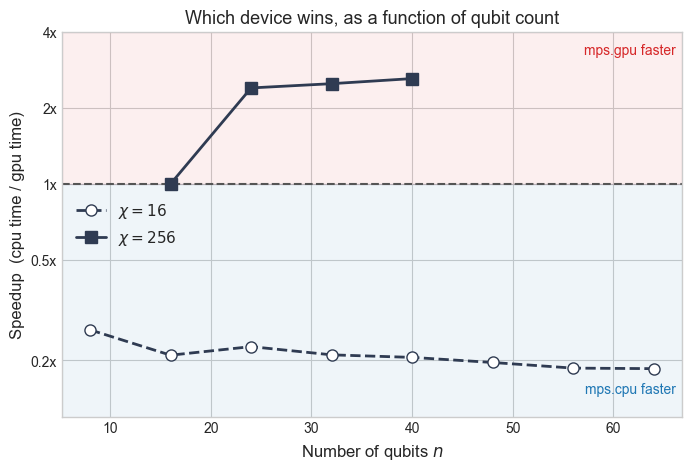

At n=40, the same circuit family gives:
  chi= 16 -> 0.21x  (GPU 4.9x SLOWER)
  chi=256 -> 2.61x  (GPU 2.6x FASTER)


In [5]:
# Head-to-head runs measured on the BlueQubit platform: the same quantum-volume
# circuit (fixed seed, depth 16, 1 shot) submitted to both mps.cpu and mps.gpu.
# Values are (cpu_time_ms, gpu_time_ms), keyed by qubit count and grouped by chi.
FLIP = {
    16: {8: (8154, 30839), 16: (4489, 21386), 24: (7527, 33169), 32: (10347, 49137),
         40: (13943, 67772), 48: (17535, 89275), 56: (21474, 115082), 64: (26436, 142363)},
    256: {16: (26267, 26291), 24: (367640, 153551), 32: (943552, 379101),
          40: (1681920, 645152)},
}

# Speedup above 1.0 means the GPU is the faster device; below 1.0 it is the slower one.
speedup = {chi: {n: cpu_ms / gpu_ms for n, (cpu_ms, gpu_ms) in runs.items()}
           for chi, runs in FLIP.items()}

fig, ax = cpu_gpu_axes("Which device wins, as a function of qubit count",
                       r"Number of qubits $n$", "Speedup  (cpu time / gpu time)")

# The horizontal line at 1.0 is the decision boundary: the shaded bands are the
# territory of each device.
ax.axhspan(1.0, 4.0, color=GPU_COLOR, alpha=0.07)
ax.axhspan(0.1, 1.0, color=CPU_COLOR, alpha=0.07)
ax.axhline(1.0, color="#555", linestyle="--", linewidth=1.5)
ax.text(0.99, 0.94, "mps.gpu faster", transform=ax.transAxes, ha="right",
        fontsize=10, color=GPU_COLOR)
ax.text(0.99, 0.06, "mps.cpu faster", transform=ax.transAxes, ha="right",
        fontsize=10, color=CPU_COLOR)

for chi, marker, style in ((16, "o", "--"), (256, "s", "-")):
    qubits = sorted(speedup[chi])
    ax.plot(qubits, [speedup[chi][n] for n in qubits], marker=marker, linestyle=style,
            color="#2f3b52", markersize=8, linewidth=2,
            markerfacecolor="white" if chi == 16 else "#2f3b52",
            label=rf"$\chi = {chi}$")

ax.set_yscale("log")
ax.set_ylim(0.12, 4.0)
ax.minorticks_off()  # otherwise the log locator adds its own labels
ax.set_yticks([0.2, 0.5, 1.0, 2.0, 4.0], labels=["0.2x", "0.5x", "1x", "2x", "4x"])
ax.legend(loc="center left", fontsize=11)
plt.show()

for n in (40,):
    print(f"At n={n}, the same circuit family gives:")
    print(f"  chi= 16 -> {speedup[16][n]:.2f}x  (GPU {1 / speedup[16][n]:.1f}x SLOWER)")
    print(f"  chi=256 -> {speedup[256][n]:.2f}x  (GPU {speedup[256][n]:.1f}x FASTER)")

Read that figure two ways.

**Follow the $\chi = 16$ line.** It never leaves CPU territory. Going from 8 qubits to 64 (an eightfold increase in width, and a $2^{56}$-fold increase in Hilbert-space dimension) does not lift it towards the boundary, let alone across it. It stays flat near $0.2\times$, meaning the GPU is consistently about five times *slower*, at every size. Qubit count simply does not move this line.

**Now compare the two lines where they overlap.** They sit on opposite sides of the boundary. At $n = 40$ the same circuit family, at the same width and the same depth, hands the GPU a $4.9\times$ loss at $\chi = 16$ and a $2.6\times$ win at $\chi = 256$. One parameter changed, and the correct device changed with it.

The mechanism is simple enough. At small $\chi$ the tensors are tiny, so each gate is a minute amount of arithmetic wrapped in a fixed cost that the GPU pays and the CPU does not: kernel launch, synchronisation, host-to-device transfer. At large $\chi$ the arithmetic dominates and the GPU's parallelism finally has something to work on.

⚠️ These runs use depth 16, while the sweeps in Section 3 use depth 10, so the two agree in direction but not in exact magnitude. A benchmark number means nothing without the conditions that produced it, and we label every table below accordingly.

### Two circuits, one width, opposite answers

If $\chi$ is what matters, then two circuits of *identical* size should be able to disagree about the right device. They can. Take a quantum-volume circuit and a QFT, both on 40 qubits.

In [6]:
from qiskit.circuit.library import quantum_volume
from qiskit.synthesis import synth_qft_full

N_QUBITS = 40

qv = quantum_volume(N_QUBITS, depth=10, seed=42)
qft = synth_qft_full(num_qubits=N_QUBITS, approximation_degree=0, do_swaps=True)


def two_qubit_gate_count(circuit):
    """Count the two-qubit operations in a circuit.

    :param circuit: a Qiskit ``QuantumCircuit``.
    :return: number of two-qubit gates.
    """
    return sum(1 for instruction in circuit.data if len(instruction.qubits) == 2)


for name, circuit in (("quantum volume", qv), ("QFT", qft)):
    print(
        f"{name:>15}: {circuit.num_qubits} qubits, "
        f"depth {circuit.depth():>4}, "
        f"{two_qubit_gate_count(circuit):>5} two-qubit gates"
    )

print(
    "\nSame width. The QV circuit entangles random pairs layer after layer, so chi"
    "\nsaturates. The QFT's controlled-phase structure generates entanglement growing"
    "\nonly as O(log n), so chi stays small no matter how wide the circuit gets. That"
    "\nmakes the matrix product state representation comparatively compact for this"
    "\ncircuit family."
)

 quantum volume: 40 qubits, depth   10,   200 two-qubit gates
            QFT: 40 qubits, depth   80,   800 two-qubit gates

Same width. The QV circuit entangles random pairs layer after layer, so chi
saturates. The QFT's controlled-phase structure generates entanglement growing
only as O(log n), so chi stays small no matter how wide the circuit gets. That
makes the matrix product state representation comparatively compact for this
circuit family.


That structural difference shows up directly in the measurements. Here is the full QFT sweep on both devices at $\chi_{\max} = 64$, a bond dimension the QFT never comes close to exhausting.

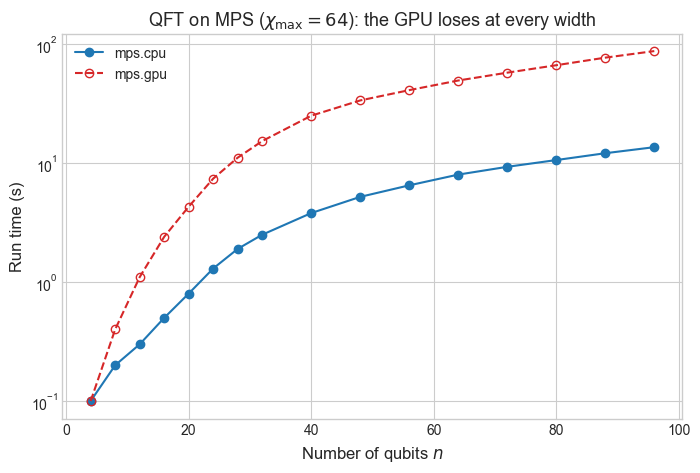

GPU penalty at n=96: 6.4x slower (87.3 s vs 13.6 s)
Penalty is flat from n=32 upward: 6.1x, 6.5x, 6.2x, 6.3x, 6.4x


In [7]:
# Full QFT (approximation_degree=0) on MPS at chi_max=64, 1 shot.
# Median platform-reported run time over 9 trials, in seconds.
QFT_CPU_S = {4: 0.1, 8: 0.2, 12: 0.3, 16: 0.5, 20: 0.8, 24: 1.3, 28: 1.9, 32: 2.5,
             40: 3.8, 48: 5.2, 56: 6.5, 64: 8.0, 72: 9.3, 80: 10.6, 88: 12.1, 96: 13.6}
QFT_GPU_S = {4: 0.1, 8: 0.4, 12: 1.1, 16: 2.4, 20: 4.3, 24: 7.4, 28: 11.1, 32: 15.3,
             40: 25.0, 48: 33.6, 56: 41.0, 64: 49.4, 72: 57.5, 80: 66.4, 88: 76.9, 96: 87.3}

ns = np.array(sorted(QFT_CPU_S))
qft_cpu = np.array([QFT_CPU_S[n] for n in ns])
qft_gpu = np.array([QFT_GPU_S[n] for n in ns])

fig, ax = cpu_gpu_axes(
    r"QFT on MPS ($\chi_{\max}=64$): the GPU loses at every width",
    r"Number of qubits $n$", "Run time (s)")
ax.plot(ns, qft_cpu, "o-", color=CPU_COLOR, label="mps.cpu")
ax.plot(ns, qft_gpu, "o--", color=GPU_COLOR, markerfacecolor="none", label="mps.gpu")
ax.set_yscale("log")
ax.legend()
plt.show()

print(f"GPU penalty at n=96: {qft_gpu[-1] / qft_cpu[-1]:.1f}x slower "
      f"({qft_gpu[-1]:.1f} s vs {qft_cpu[-1]:.1f} s)")
print("Penalty is flat from n=32 upward: "
      + ", ".join(f"{QFT_GPU_S[n] / QFT_CPU_S[n]:.1f}x" for n in (32, 48, 64, 80, 96)))

The GPU is roughly $6\times$ slower across the entire sweep, and the penalty does not shrink as the circuit grows. It is still there at 96 qubits. A rule of the form *"use the GPU for big circuits"* would get this backwards at every single point.

💡 The practical reading: before choosing a device, ask what $\chi$ the circuit will demand. Low-entanglement structure (QFT, shallow circuits, product-state preparation, anything near-Clifford) means small $\chi$, which means CPU.

### Check it on your own account

Everything above is pre-computed, which is a reasonable thing to be sceptical of. The cell below is the smallest experiment that reproduces the flip first-hand: one circuit, two bond dimensions, both devices. It submits four jobs and takes something like five to ten minutes, most of it in the $\chi = 256$ CPU run.

⚠️ This is the one cell in the tutorial that costs real compute time. Everything else runs offline.

In [8]:
# Four jobs: the same circuit at two bond dimensions on both MPS devices.
results = {}
for chi in (16, 256):
    for device in ("mps.cpu", "mps.gpu"):
        circuit = quantum_volume(24, depth=10, seed=42)
        job = bq.run(circuit, device=device,
                     options={"mps_bond_dimension": chi}, shots=1)
        results[(chi, device)] = job.run_time_ms

print(f"{'chi':>6} {'mps.cpu':>11} {'mps.gpu':>11} {'speedup':>9}  verdict")
for chi in (16, 256):
    cpu_ms = results[(chi, "mps.cpu")]
    gpu_ms = results[(chi, "mps.gpu")]
    ratio = cpu_ms / gpu_ms
    print(f"{chi:>6} {cpu_ms / 1000:>9.1f} s {gpu_ms / 1000:>9.1f} s "
          f"{ratio:>8.2f}x  {'GPU wins' if ratio > 1 else 'CPU wins'}")

   chi     mps.cpu     mps.gpu   speedup  verdict
    16       2.8 s      14.1 s     0.20x  CPU wins
   256     154.8 s      89.7 s     1.73x  GPU wins


## 3. Where each device wins

Section 2 established that $\chi$ is the axis. Now we locate the actual crossings. Each subsection below is one sweep from the benchmarking study [[1]](#ref-1): a single parameter varied, five trials per point, medians reported, failed runs excluded.

### 3a. State vector: `cpu` versus `gpu`

The statevector simulator backends have no approximation controls, so the only question is which one to use. The answer depends on $n$ alone, and it flips much earlier than most people expect.

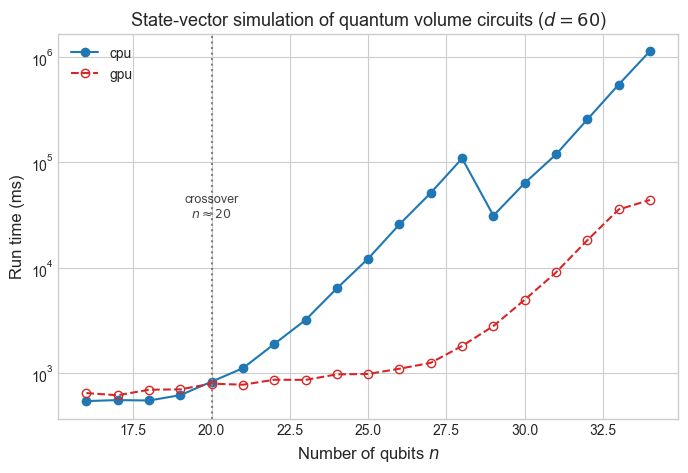

n= 16  cpu/gpu =   0.84x   -> use cpu
n= 18  cpu/gpu =   0.79x   -> use cpu
n= 20  cpu/gpu =   1.05x   -> use gpu
n= 24  cpu/gpu =   6.53x   -> use gpu
n= 28  cpu/gpu =  59.91x   -> use gpu
n= 29  cpu/gpu =  11.12x   -> use gpu
n= 34  cpu/gpu =  25.74x   -> use gpu


In [13]:
# Quantum volume circuits at depth 60, exact state-vector simulation.
# Median platform-reported run time over 5 trials, in milliseconds.
SV_CPU_MS = {16: 545, 17: 557, 18: 552, 19: 620, 20: 833, 21: 1117, 22: 1893,
             23: 3202, 24: 6375, 25: 12204, 26: 25769, 27: 51266, 28: 108730,
             29: 31185, 30: 63522, 31: 118734, 32: 254392, 33: 544604, 34: 1130920}
SV_GPU_MS = {16: 649, 17: 619, 18: 698, 19: 704, 20: 797, 21: 779, 22: 868,
             23: 866, 24: 976, 25: 985, 26: 1104, 27: 1256, 28: 1815,
             29: 2805, 30: 4980, 31: 9035, 32: 18246, 33: 35671, 34: 43940}

sv_n = np.array(sorted(SV_CPU_MS))
sv_cpu = np.array([SV_CPU_MS[n] for n in sv_n])
sv_gpu = np.array([SV_GPU_MS[n] for n in sv_n])

fig, ax = cpu_gpu_axes("State-vector simulation of quantum volume circuits ($d=60$)",
                       r"Number of qubits $n$", "Run time (ms)")
ax.plot(sv_n, sv_cpu, "o-", color=CPU_COLOR, label="cpu")
ax.plot(sv_n, sv_gpu, "o--", color=GPU_COLOR, markerfacecolor="none", label="gpu")
ax.set_yscale("log")
ax.axvline(20, color="grey", linestyle=":", linewidth=1.5)
ax.annotate("crossover\n$n \\approx 20$", xy=(20, 3e4), ha="center", fontsize=9, color="#444")
ax.legend()
plt.show()

for n in (16, 18, 20, 24, 28, 29, 34):
    ratio = SV_CPU_MS[n] / SV_GPU_MS[n]
    verdict = "gpu" if ratio > 1 else "cpu"
    print(f"n={n:>3}  cpu/gpu = {ratio:>6.2f}x   -> use {verdict}")

Below about 20 qubits the CPU is the faster device: the state is small, and the GPU's fixed per-launch overhead is a larger share of the work than the work itself. Above the crossover the gap opens quickly, and by 34 qubits the GPU is finishing in 44 seconds what costs the CPU nearly 19 minutes.

Two readings of this plot need spelling out, because both are the kind of thing a benchmark can quietly mislead you about.

**The $60\times$ peak at $n = 28$ is not a real GPU advantage.** Look at the CPU series across $n = 28 \to 29$: it *drops* from 108.7 s to 31.2 s. Runtime does not fall when you add a qubit. What happened is a hardware transition on the managed platform, where larger jobs are provisioned onto a bigger configuration, so the apparent peak is an artefact of the CPU baseline changing underneath the sweep. The defensible claim above $n = 29$ is a steady $11$ to $26\times$, not $60\times$.

**Depth does not move the crossover.** The same sweep at depths 30, 90, 120, and 150 puts the crossing in the same place, near $n \approx 19$ to $20$. Per-gate cost is what differs between the devices, and adding layers scales both sides equally.

### 3b. MPS: bond dimension is the axis

This is the central measurement of the tutorial. For an MPS simulator, bond dimension is the primary performance variable. We fix $n = 40$ and $d = 10$, take a single shot so that sampling cost is negligible, and sweep $\chi$ over a factor of 48.

In [14]:
# Quantum volume on MPS at n=40, d=10, 1 shot, sweeping the bond dimension.
# Median platform-reported run time over 5 trials, in seconds.
BOND_CPU_S = {32: 21.2, 64: 59.8, 128: 152.2, 256: 721.4,
              384: 2007.2, 512: 4524.2, 768: 13009.1, 1024: 28111.3}
BOND_GPU_S = {32: 32.6, 64: 63.0, 128: 144.9, 256: 355.3, 384: 661.8,
              512: 1141.4, 768: 2373.2, 1024: 4250.3, 1280: 6357.2, 1536: 9271.6}


def fit_power_law(xs, ys):
    """Fit T = a * x**alpha in log-log space.

    :param xs: independent variable values.
    :param ys: measured runtimes.
    :return: ``(a, alpha, alpha_stderr)``.
    """
    def model(log_x, log_a, alpha):
        return log_a + alpha * log_x

    popt, pcov = curve_fit(model, np.log(xs), np.log(ys), p0=[0.0, 2.0])
    return np.exp(popt[0]), popt[1], np.sqrt(np.diag(pcov))[1]


chi_cpu = np.array(sorted(BOND_CPU_S))
chi_gpu = np.array(sorted(BOND_GPU_S))
t_cpu = np.array([BOND_CPU_S[c] for c in chi_cpu])
t_gpu = np.array([BOND_GPU_S[c] for c in chi_gpu])

a_cpu, alpha_cpu, err_cpu = fit_power_law(chi_cpu, t_cpu)
a_gpu, alpha_gpu, err_gpu = fit_power_law(chi_gpu, t_gpu)

print(f"mps.cpu :  T = {a_cpu:.3g} * chi^{alpha_cpu:.2f} +/- {err_cpu:.2f}")
print(f"mps.gpu :  T = {a_gpu:.3g} * chi^{alpha_gpu:.2f} +/- {err_gpu:.2f}")
print(f"\nGPU advantage grows as chi^{alpha_cpu - alpha_gpu:.2f}")

mps.cpu :  T = 0.00937 * chi^2.10 +/- 0.11
mps.gpu :  T = 0.13 * chi^1.48 +/- 0.07

GPU advantage grows as chi^0.61


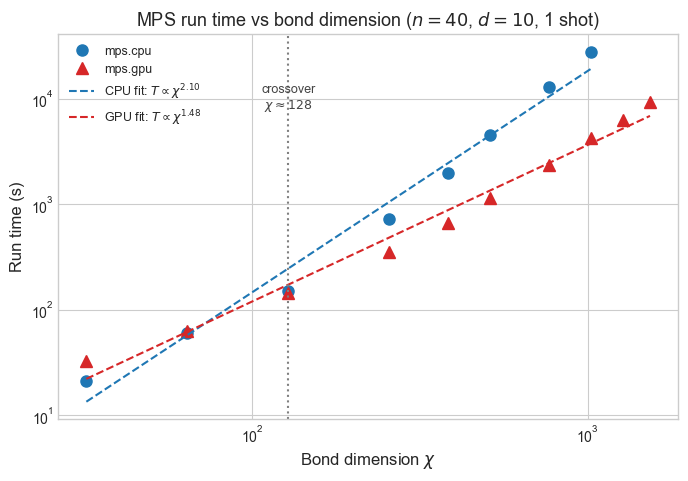

   chi      mps.cpu      mps.gpu   cpu/gpu
    32       21.2 s       32.6 s     0.65x
    64       59.8 s       63.0 s     0.95x
   128      152.2 s      144.9 s     1.05x
   256      721.4 s      355.3 s     2.03x
   384    2,007.2 s      661.8 s     3.03x
   512    4,524.2 s    1,141.4 s     3.96x
   768   13,009.1 s    2,373.2 s     5.48x
  1024   28,111.3 s    4,250.3 s     6.61x
  1280   unavailable    6,357.2 s         -
  1536   unavailable    9,271.6 s         -


In [15]:
fig, ax = cpu_gpu_axes(r"MPS run time vs bond dimension ($n=40$, $d=10$, 1 shot)",
                       r"Bond dimension $\chi$", "Run time (s)")
ax.plot(chi_cpu, t_cpu, "o", color=CPU_COLOR, markersize=8, label="mps.cpu")
ax.plot(chi_gpu, t_gpu, "^", color=GPU_COLOR, markersize=8, label="mps.gpu")

grid_cpu = np.logspace(np.log10(chi_cpu.min()), np.log10(chi_cpu.max()), 100)
grid_gpu = np.logspace(np.log10(chi_gpu.min()), np.log10(chi_gpu.max()), 100)
ax.plot(grid_cpu, a_cpu * grid_cpu ** alpha_cpu, "--", color=CPU_COLOR,
        label=rf"CPU fit: $T \propto \chi^{{{alpha_cpu:.2f}}}$")
ax.plot(grid_gpu, a_gpu * grid_gpu ** alpha_gpu, "--", color=GPU_COLOR,
        label=rf"GPU fit: $T \propto \chi^{{{alpha_gpu:.2f}}}$")

ax.axvline(128, color="grey", linestyle=":", linewidth=1.5)
ax.annotate("crossover\n$\\chi \\approx 128$", xy=(128, 8000), ha="center",
            fontsize=9, color="#444")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(loc="upper left", fontsize=9)
plt.show()

print(f"{'chi':>6} {'mps.cpu':>12} {'mps.gpu':>12} {'cpu/gpu':>9}")
for chi in sorted(set(BOND_CPU_S) | set(BOND_GPU_S)):
    cpu_s = BOND_CPU_S.get(chi)
    gpu_s = BOND_GPU_S.get(chi)
    cpu_txt = f"{cpu_s:>10,.1f} s" if cpu_s else "  unavailable"
    ratio = f"{cpu_s / gpu_s:>8.2f}x" if cpu_s else "        -"
    print(f"{chi:>6} {cpu_txt} {gpu_s:>10,.1f} s {ratio}")

In [16]:
# The crossover is the load-bearing claim of this tutorial, so assert it rather
# than trusting the prose to stay in sync with the data.
shared_chi = sorted(set(BOND_CPU_S) & set(BOND_GPU_S))
ratios = {c: BOND_CPU_S[c] / BOND_GPU_S[c] for c in shared_chi}

assert ratios[64] < 1.0 < ratios[256], "crossover is no longer between chi=64 and chi=256"
assert alpha_gpu < alpha_cpu, "GPU is no longer the sub-quadratic backend"
print(f"OK  CPU wins at chi=64 ({ratios[64]:.2f}x), GPU wins at chi=256 ({ratios[256]:.2f}x)")
print(f"OK  GPU exponent {alpha_gpu:.2f} < CPU exponent {alpha_cpu:.2f}")

OK  CPU wins at chi=64 (0.95x), GPU wins at chi=256 (2.03x)
OK  GPU exponent 1.48 < CPU exponent 2.10


The CPU scaling is close to quadratic and the GPU scaling is distinctly sub-quadratic, so the *ratio* between them is itself a growing function of $\chi$:

$$S(\chi) \;=\; \frac{T_{\mathrm{CPU}}(\chi)}{T_{\mathrm{GPU}}(\chi)} \;\propto\; \chi^{0.61}.$$

The GPU advantage is largest exactly where simulation hurts most. (The published study fits the same data with the spread of each point as a weight, and reports slightly softer exponents of $\chi^{2.03}$ and $\chi^{1.49}$, giving $\chi^{0.55}$ [[1]](#ref-1). The unweighted fit above is what these medians give on their own; the conclusion is the same either way.) That gives us the rule:

- $\chi \lesssim 128$: use `mps.cpu`.
- $\chi \gtrsim 256$: use `mps.gpu`, worth $2\times$ at $\chi = 256$ and around $7\times$ by $\chi = 1024$.
- $\chi > 1024$: `mps.gpu` is the only option. The CPU runs in this sweep did not complete at all.

That last point is a different kind of statement from the others. Above a certain bond dimension the CPU backend stops being *slow* and starts being *unavailable*: the jobs exceed the platform's runtime allowance and are terminated. At large $\chi$, device choice decides whether you get an answer at all, not merely how fast it arrives.

➕ At $\chi = 1536$ a single GPU run takes about 2.6 hours. Extrapolating the two fitted curves out to $\chi = 5000$ projects roughly 11.7 hours on GPU against 119.2 hours on CPU. Treat that as illustrative rather than predictive: the $\mathcal{O}(\chi^{3})$ cost of the SVD step must eventually dominate on both backends, and these sweeps do not yet reach the point where it does.

### 3c. Qubits and depth are the weak axes

If $\chi$ moves the exponent, what do $n$ and $d$ move? Only the constant. Both sweeps below hold $\chi = 256$ fixed.

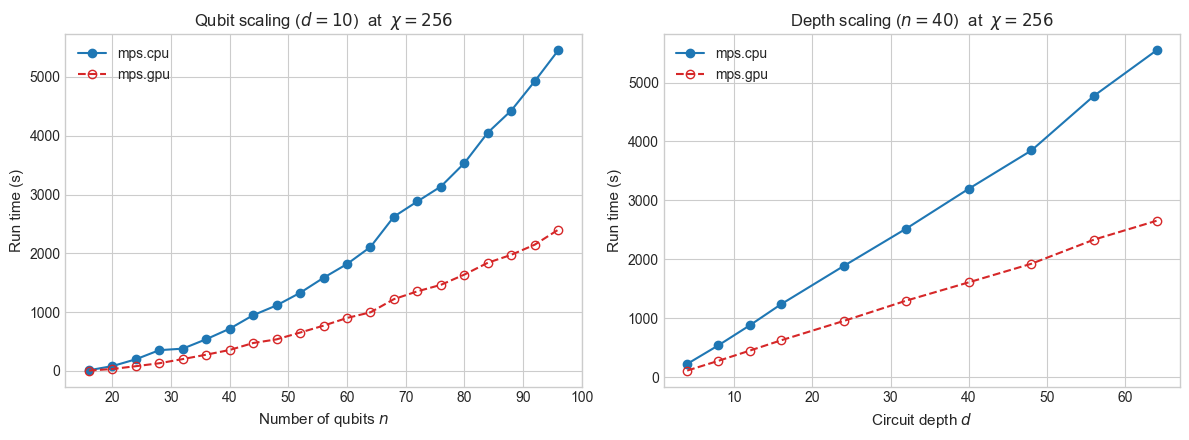

cpu/gpu across n = 32..96 : 1.88x to 2.29x
cpu/gpu across d =  4..64 : 1.94x to 2.09x


In [17]:
# Both sweeps: quantum volume on MPS at chi=256, 1 shot.
# Median platform-reported run time over 5 trials, in seconds.
QUBIT_CPU_S = {16: 12.4, 20: 82.8, 24: 198.5, 28: 353.7, 32: 379.5, 36: 539.9,
               40: 718.7, 44: 948.0, 48: 1115.2, 52: 1328.5, 56: 1584.3, 60: 1817.9,
               64: 2108.7, 68: 2623.9, 72: 2882.6, 76: 3135.7, 80: 3533.2, 84: 4052.1,
               88: 4427.7, 92: 4925.6, 96: 5450.6}
QUBIT_GPU_S = {16: 6.9, 20: 33.9, 24: 81.2, 28: 131.4, 32: 202.3, 36: 277.0,
               40: 357.1, 44: 475.3, 48: 537.7, 52: 653.0, 56: 770.4, 60: 901.2,
               64: 997.4, 68: 1221.4, 72: 1354.1, 76: 1464.2, 80: 1638.6, 84: 1840.0,
               88: 1974.6, 92: 2147.2, 96: 2401.4}

DEPTH_CPU_S = {4: 226.1, 8: 542.3, 12: 880.5, 16: 1238.5, 24: 1886.4,
               32: 2521.4, 40: 3197.6, 48: 3846.7, 56: 4774.1, 64: 5545.6}
DEPTH_GPU_S = {4: 113.1, 8: 278.9, 12: 451.5, 16: 626.1, 24: 954.3,
               32: 1299.3, 40: 1610.1, 48: 1925.3, 56: 2334.2, 64: 2654.2}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (cpu_d, gpu_d, xlabel, title) in zip(axes, (
        (QUBIT_CPU_S, QUBIT_GPU_S, r"Number of qubits $n$", r"Qubit scaling ($d=10$)"),
        (DEPTH_CPU_S, DEPTH_GPU_S, "Circuit depth $d$", r"Depth scaling ($n=40$)"))):
    xs = np.array(sorted(cpu_d))
    ax.plot(xs, [cpu_d[x] for x in xs], "o-", color=CPU_COLOR, label="mps.cpu")
    ax.plot(xs, [gpu_d[x] for x in xs], "o--", color=GPU_COLOR,
            markerfacecolor="none", label="mps.gpu")
    ax.set_title(title + r"  at  $\chi=256$", fontsize=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel("Run time (s)", fontsize=11)
    ax.legend()

plt.tight_layout()
plt.show()

qubit_ratios = [QUBIT_CPU_S[n] / QUBIT_GPU_S[n] for n in sorted(QUBIT_CPU_S) if n >= 32]
depth_ratios = [DEPTH_CPU_S[d] / DEPTH_GPU_S[d] for d in sorted(DEPTH_CPU_S)]
print(f"cpu/gpu across n = 32..96 : {min(qubit_ratios):.2f}x to {max(qubit_ratios):.2f}x")
print(f"cpu/gpu across d =  4..64 : {min(depth_ratios):.2f}x to {max(depth_ratios):.2f}x")

Both curves are straight and both ratios are flat. Across a sixfold change in depth and a threefold change in qubit count, the CPU-to-GPU ratio never leaves a narrow band around $2\times$, and that band is set entirely by $\chi$. Run the same depth sweep at $\chi = 128$ instead and the ratio sits near $1.1\times$ throughout.

This is the asymmetry that justifies the whole approach. Widening or deepening a circuit makes *both* devices proportionally slower and leaves your decision unchanged. Raising $\chi$ changes which device is correct.

### 3d. Pauli path: $\delta$ is the axis

Pauli-path simulation has the same shape of story with a different knob. The truncation threshold $\delta$ controls how many Pauli terms survive, and therefore how much parallel work there is to do. Below is IBM's 127-qubit kicked-Ising circuit at 20 Trotter steps, measuring $\langle Z_{62} \rangle$, the same benchmark used throughout the literature.

➡️ For how Pauli-path propagation works and how to choose $\delta$, see the [Pauli-Path Simulation tutorial](https://app.bluequbit.io/tutorial/pauli-path-simulation). Here we care only about which device to point at it.

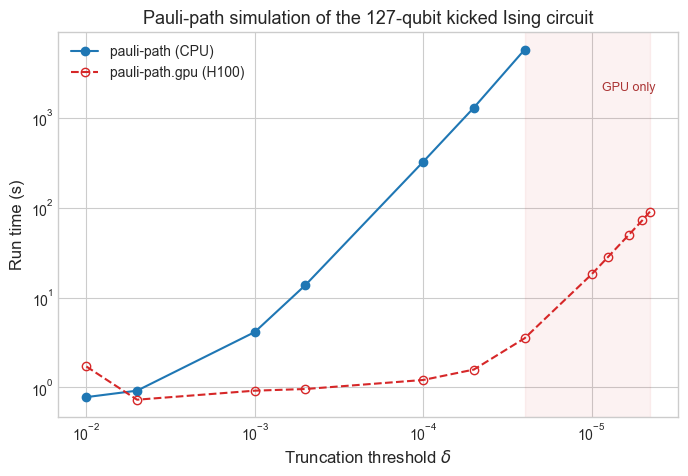

     delta          cpu        gpu    cpu/gpu
      0.01       0.78 s     1.71 s       0.5x
     0.005       0.92 s     0.73 s       1.3x
     0.001       4.13 s     0.92 s       4.5x
    0.0005      13.77 s     0.96 s      14.3x
    0.0001     323.50 s     1.21 s     267.4x
     5e-05    1295.07 s     1.58 s     819.7x
   2.5e-05    5710.51 s     3.52 s    1622.3x


In [18]:
# 127-qubit kicked Ising, 20 Trotter steps, observable <Z_62>, theta_X = pi/4.
# Median run time in seconds; GPU figures are an NVIDIA H100.
PPS_DELTA = [1e-2, 5e-3, 1e-3, 5e-4, 1e-4, 5e-5, 2.5e-5]
PPS_CPU_S = [0.78, 0.92, 4.13, 13.77, 323.50, 1295.07, 5710.51]
PPS_GPU_S = [1.71, 0.73, 0.92, 0.96, 1.21, 1.58, 3.52]

# GPU only: no CPU backend in the study reached these thresholds.
PPS_DELTA_GPU_ONLY = [1e-5, 8e-6, 6e-6, 5e-6, 4.5e-6]
PPS_GPU_ONLY_S = [18.10, 28.14, 50.00, 72.11, 90.31]

fig, ax = cpu_gpu_axes(r"Pauli-path simulation of the 127-qubit kicked Ising circuit",
                       r"Truncation threshold $\delta$", "Run time (s)")
ax.plot(PPS_DELTA, PPS_CPU_S, "o-", color=CPU_COLOR, label="pauli-path (CPU)")
ax.plot(PPS_DELTA + PPS_DELTA_GPU_ONLY, PPS_GPU_S + PPS_GPU_ONLY_S, "o--",
        color=GPU_COLOR, markerfacecolor="none", label="pauli-path.gpu (H100)")
ax.axvspan(min(PPS_DELTA_GPU_ONLY), min(PPS_DELTA), color="#d62728", alpha=0.06)
ax.annotate("GPU only", xy=(6e-6, 2000), fontsize=9, color="#a33", ha="center")
ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.legend()
plt.show()

print(f"{'delta':>10} {'cpu':>12} {'gpu':>10} {'cpu/gpu':>10}")
for delta, cpu_s, gpu_s in zip(PPS_DELTA, PPS_CPU_S, PPS_GPU_S):
    print(f"{delta:>10.2g} {cpu_s:>10.2f} s {gpu_s:>8.2f} s {cpu_s / gpu_s:>9.1f}x")

The same pattern again. At coarse thresholds the CPU wins outright, because at $\delta = 10^{-2}$ there are only a few hundred Pauli terms and the GPU's setup cost dominates, and the crossover sits near $\delta \approx 10^{-3}$. Past it the curves diverge violently, because the CPU cost grows with the term count while the GPU absorbs millions of terms almost flat.

And, as with MPS at large $\chi$, the far end of the sweep is a question of availability rather than speed. Below $\delta = 10^{-5}$ no CPU backend in the study finished at all.

### 3e. Shots are the fourth axis

There is one more axis, and it is the one people forget. An MPS job has two phases that behave completely differently: **building** the MPS by absorbing gates and truncating, and **sampling** bitstrings from the finished object. Every sweep so far used a single shot, which means every figure above measured build time almost exclusively. Ask for more shots and the balance shifts.

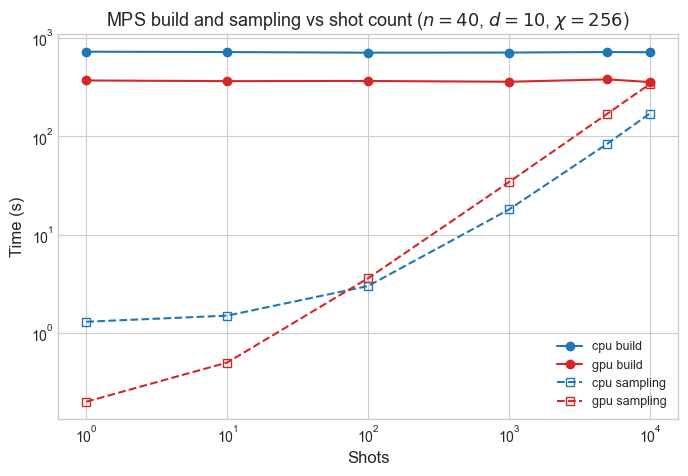

  shots   cpu total   gpu total   cpu/gpu
      1     724.8 s     369.2 s     1.96x
     10     719.1 s     363.8 s     1.98x
    100     710.2 s     368.3 s     1.93x
   1000     727.2 s     392.3 s     1.85x
   5000     802.4 s     548.2 s     1.46x
  10000     885.4 s     694.9 s     1.27x

cpu sampling: 17 ms/shot
gpu sampling: 34 ms/shot


In [19]:
# Quantum volume on MPS at n=40, d=10, chi=256, sweeping the shot count.
# Median over 5 trials, in seconds. Build time comes from the job's
# run_results["mps_build_time"]; sampling time is the remainder.
SHOTS = [1, 10, 100, 1000, 5000, 10000]
BUILD_CPU_S = [723.5, 717.6, 707.2, 709.2, 718.2, 715.2]
BUILD_GPU_S = [369.0, 363.3, 364.7, 358.1, 378.4, 355.4]
SAMPLE_CPU_S = [1.3, 1.5, 3.0, 18.0, 84.2, 170.2]
SAMPLE_GPU_S = [0.2, 0.5, 3.6, 34.2, 169.8, 339.5]

fig, ax = cpu_gpu_axes(r"MPS build and sampling vs shot count ($n=40$, $d=10$, $\chi=256$)",
                       "Shots", "Time (s)")
ax.plot(SHOTS, BUILD_CPU_S, "o-", color=CPU_COLOR, label="cpu build")
ax.plot(SHOTS, BUILD_GPU_S, "o-", color=GPU_COLOR, label="gpu build")
ax.plot(SHOTS, SAMPLE_CPU_S, "s--", color=CPU_COLOR, markerfacecolor="none",
        label="cpu sampling")
ax.plot(SHOTS, SAMPLE_GPU_S, "s--", color=GPU_COLOR, markerfacecolor="none",
        label="gpu sampling")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(fontsize=9)
plt.show()

print(f"{'shots':>7} {'cpu total':>11} {'gpu total':>11} {'cpu/gpu':>9}")
for i, shots in enumerate(SHOTS):
    total_cpu = BUILD_CPU_S[i] + SAMPLE_CPU_S[i]
    total_gpu = BUILD_GPU_S[i] + SAMPLE_GPU_S[i]
    print(f"{shots:>7} {total_cpu:>9.1f} s {total_gpu:>9.1f} s {total_cpu / total_gpu:>8.2f}x")

print(f"\ncpu sampling: {1000 * (SAMPLE_CPU_S[-1] - SAMPLE_CPU_S[0]) / 10000:.0f} ms/shot")
print(f"gpu sampling: {1000 * (SAMPLE_GPU_S[-1] - SAMPLE_GPU_S[0]) / 10000:.0f} ms/shot")

Build time is flat on either device, whatever number of shots you ask for, so the entire $2\times$ GPU advantage at this bond dimension lives in the build phase. Sampling is a different story: it is linear in shots, and the GPU is about **twice as slow per shot** as the CPU.

So the GPU's end-to-end advantage decays as you ask for more samples, from $1.96\times$ at one shot to $1.27\times$ at ten thousand, with break-even extrapolating to somewhere near forty thousand shots. `mps.gpu` is the device for construction-bound work: large $\chi$, few shots, many circuits. A sampling-bound workload at modest $\chi$ belongs on the CPU.

## 4. The decision procedure

Collecting the crossovers into one place gives a rule you can apply before submitting anything.

| Question | Threshold | Rule |
|---|---|---|
| Do you need the full state? | $n \lesssim 34$ | state vector; beyond that it is out of reach |
| State vector, which device? | $n \approx 20$ | below, `cpu`; above, `gpu` ($11$ to $26\times$ at $n \geq 29$) |
| MPS, which device? | $\chi \approx 128$ | below, `mps.cpu`; above $256$, `mps.gpu` ($2$ to $7\times$) |
| MPS at very large $\chi$? | $\chi > 1024$ | `mps.gpu` only; CPU runs are terminated |
| Low-entanglement family? | $\chi \lesssim 64$ | `mps.cpu`; the GPU is a flat $\sim6\times$ penalty even at $n = 96$ |
| Many shots? | $\gtrsim 5000$ | the GPU advantage decays; near $40{,}000$ it is gone |
| Expectation values only? | any $n$ | `pauli-path`; choose the device by $\delta$, crossover $\approx 10^{-3}$ |

The same rules, as a function:

In [20]:
def choose_device(n_qubits, chi_est=None, delta=None, shots=1, needs_statevector=False):
    """Recommend a BlueQubit device from a circuit's structure.

    The thresholds are empirical; see the crossovers measured in Sections 3a-3d.

    :param n_qubits: number of qubits in the circuit.
    :param chi_est: estimated MPS bond dimension the circuit will demand.
    :param delta: Pauli-path truncation threshold, if using PPS.
    :param shots: number of shots to draw.
    :param needs_statevector: whether the full state vector is required.
    :return: ``(device, reason)``.
    """
    if needs_statevector or (chi_est is None and delta is None):
        if n_qubits > 34:
            return None, f"{n_qubits} qubits exceeds the state-vector wall; estimate chi or use PPS"
        if n_qubits < 20:
            return "cpu", f"below the n~20 crossover, GPU launch overhead dominates"
        return "gpu", f"above the n~20 crossover, GPU is 11-26x faster by n=29"

    if delta is not None:
        if delta >= 1e-3:
            return "pauli-path", f"coarse threshold {delta:g}; too few Pauli terms to occupy a GPU"
        return "pauli-path.gpu", f"fine threshold {delta:g}; below 1e-5 the GPU is the only option"

    if chi_est > 1024:
        return "mps.gpu", f"chi={chi_est} exceeds what the CPU backend completes at all"
    if chi_est < 128:
        return "mps.cpu", f"chi={chi_est} is below the chi~128 crossover; tensors too small for a GPU"
    if shots >= 40000:
        return "mps.cpu", f"{shots:,} shots makes this sampling-bound, where CPU sampling is 2x faster"
    return "mps.gpu", f"chi={chi_est} is above the chi~128 crossover; advantage grows as chi^0.61"


EXAMPLES = [
    ("Bell state, need amplitudes",        dict(n_qubits=2, needs_statevector=True)),
    ("28-qubit QV, full distribution",     dict(n_qubits=28, needs_statevector=True)),
    ("40-qubit QFT",                       dict(n_qubits=40, chi_est=64)),
    ("40-qubit QV, depth 10",              dict(n_qubits=40, chi_est=256)),
    ("46-qubit peaked circuit",            dict(n_qubits=46, chi_est=1536)),
    ("40-qubit QV, 100k shots",            dict(n_qubits=40, chi_est=256, shots=100_000)),
    ("127-qubit kicked Ising, coarse",     dict(n_qubits=127, delta=1e-2)),
    ("127-qubit kicked Ising, converged",  dict(n_qubits=127, delta=5e-6)),
]

for label, kwargs in EXAMPLES:
    device, reason = choose_device(**kwargs)
    print(f"{label:>34} -> {str(device):<16} {reason}")

       Bell state, need amplitudes -> cpu              below the n~20 crossover, GPU launch overhead dominates
    28-qubit QV, full distribution -> gpu              above the n~20 crossover, GPU is 11-26x faster by n=29
                      40-qubit QFT -> mps.cpu          chi=64 is below the chi~128 crossover; tensors too small for a GPU
             40-qubit QV, depth 10 -> mps.gpu          chi=256 is above the chi~128 crossover; advantage grows as chi^0.61
           46-qubit peaked circuit -> mps.gpu          chi=1536 exceeds what the CPU backend completes at all
           40-qubit QV, 100k shots -> mps.cpu          100,000 shots makes this sampling-bound, where CPU sampling is 2x faster
    127-qubit kicked Ising, coarse -> pauli-path       coarse threshold 0.01; too few Pauli terms to occupy a GPU
 127-qubit kicked Ising, converged -> pauli-path.gpu   fine threshold 5e-06; below 1e-5 the GPU is the only option


Two caveats keep this honest.

⚠️ **The speedups are upper bounds.** As noted at the top of Section 3, the CPU side of every comparison is a small provisioned configuration. On a well-parallelised many-core CPU each gap would narrow. What survives that correction is the *ordering* and the *shape*: which device wins in which regime, and the fact that the GPU's advantage grows with $\chi$. Those come from comparing the same implementation on different hardware.

⚠️ **`chi_est` is an estimate, and everything hinges on it.** The function above is only as good as the bond dimension you feed it, and there is no way to read the required $\chi$ off a circuit exactly without simulating it. In practice you estimate from structure (one-dimensional and shallow means small, all-to-all and deep means large) and then verify. Section 5 is about that verification, and about what happens when you skip it.

## 5. Trusting the answer

A statevector simulator either finishes or runs out of memory. Approximate quantum circuit simulation has a third, more dangerous option: it can finish quickly and hand you a wrong number with no indication that anything went wrong. Choosing the right device does nothing to protect you from this.

Consider a 46-qubit peaked circuit, engineered so that one bitstring carries far more probability than any other. We can try to recover that bitstring from single-qubit $\langle Z_i \rangle$ expectations, and score the result by what fraction of the 46 bits we get right. Sweeping $\chi$ on both devices gives the following.

In [21]:
# A 46-qubit peaked circuit (1320 RZZ gates), 1 shot, with a pauli_sum of one
# local Z per qubit. Median over 5 trials.
# Values are (overlap_percent, runtime_seconds).
PEAKED_CPU = {4: (50.0, 9.4), 8: (80.4, 10.9), 16: (76.1, 17.7), 32: (91.3, 88.5),
              64: (84.8, 261.5), 128: (89.1, 1241.0), 256: (91.3, 6543.4)}
PEAKED_GPU = {4: (50.0, 89.6), 8: (80.4, 108.5), 16: (76.1, 150.1), 32: (91.3, 251.5),
              64: (84.8, 504.4), 128: (89.1, 1059.4), 256: (91.3, 2884.4),
              512: (97.8, 8924.8), 1024: (97.8, 33088.4), 1536: (100.0, 76210.5)}

print(f"{'chi':>6} {'cpu overlap':>12} {'gpu overlap':>12}   {'cpu time':>11} {'gpu time':>11}")
for chi in sorted(set(PEAKED_CPU) | set(PEAKED_GPU)):
    cpu = PEAKED_CPU.get(chi)
    gpu = PEAKED_GPU.get(chi)
    cpu_ov = f"{cpu[0]:>10.1f}%" if cpu else "           -"
    gpu_ov = f"{gpu[0]:>10.1f}%" if gpu else "           -"
    cpu_t = f"{cpu[1]:>9,.0f} s" if cpu else "          -"
    gpu_t = f"{gpu[1]:>9,.0f} s" if gpu else "          -"
    print(f"{chi:>6} {cpu_ov} {gpu_ov}   {cpu_t} {gpu_t}")

shared = sorted(set(PEAKED_CPU) & set(PEAKED_GPU))
assert all(PEAKED_CPU[c][0] == PEAKED_GPU[c][0] for c in shared), "overlap differs by device"
print(f"\nOK  overlap is identical on both devices at every shared chi: {shared}")

   chi  cpu overlap  gpu overlap      cpu time    gpu time
     4       50.0%       50.0%           9 s        90 s
     8       80.4%       80.4%          11 s       108 s
    16       76.1%       76.1%          18 s       150 s
    32       91.3%       91.3%          88 s       252 s
    64       84.8%       84.8%         262 s       504 s
   128       89.1%       89.1%       1,241 s     1,059 s
   256       91.3%       91.3%       6,543 s     2,884 s
   512            -       97.8%             -     8,925 s
  1024            -       97.8%             -    33,088 s
  1536            -      100.0%             -    76,210 s

OK  overlap is identical on both devices at every shared chi: [4, 8, 16, 32, 64, 128, 256]


The assertion at the bottom of that cell is the point of the section:

> **Accuracy is a $\chi$ question, not an MPS simulator device question.** At every bond dimension where both devices ran, they agree on the answer to the decimal. The GPU is not more accurate, only faster, and speed buys you a larger matrix product state bond dimension within a fixed budget. That is what buys accuracy.

Read the runtime columns alongside the overlap column and the trade becomes concrete. The CPU stops at $\chi = 256$ after nearly two hours, having recovered 91.3% of the bits. The GPU keeps going to $\chi = 1536$ and reaches 100%. Both are simulating the same circuit correctly, for their respective definitions of "correctly".

Notice also that the overlap column is **not monotonic**: 80.4% at $\chi = 8$ drops to 76.1% at $\chi = 16$, and 91.3% at $\chi = 32$ drops to 84.8% at $\chi = 64$. Refining the approximation improves some marginals while flipping others across the sign boundary. A single point on this curve tells you nothing; only the trend does.

The same warning applies to Pauli path, where the error against the converged value $O_{\mathrm{exact}} = 0.2955$ [[3]](#ref-3) behaves like this:

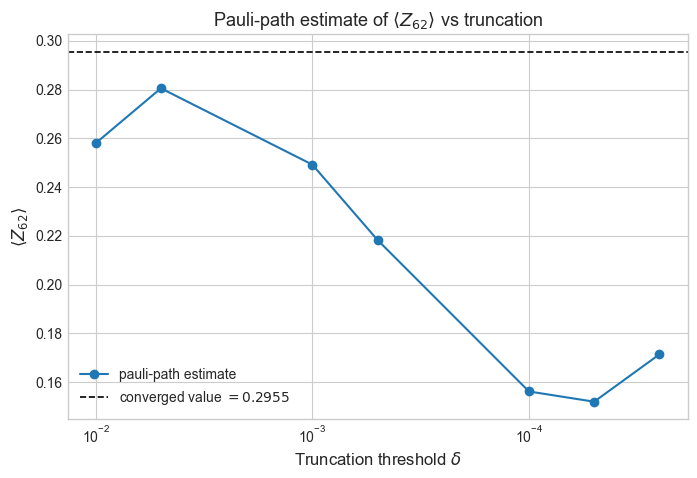

     delta   estimate     error
      0.01     0.2580    0.0375
     0.005     0.2805    0.0150
     0.001     0.2492    0.0463
    0.0005     0.2183    0.0772
    0.0001     0.1562    0.1393
     5e-05     0.1520    0.1435
   2.5e-05     0.1714    0.1241

Tightening delta from 1e-2 to 5e-5 makes the answer WORSE, not better.


In [22]:
# <Z_62> as a function of the truncation threshold, on the pauli-path device.
# Median of 5 trials.
PPS_EXPECTATION = [0.2580, 0.2805, 0.2492, 0.2183, 0.1562, 0.1520, 0.1714]
O_EXACT = 0.2955

fig, ax = cpu_gpu_axes(r"Pauli-path estimate of $\langle Z_{62} \rangle$ vs truncation",
                       r"Truncation threshold $\delta$", r"$\langle Z_{62} \rangle$")
ax.plot(PPS_DELTA, PPS_EXPECTATION, "o-", color=CPU_COLOR, label="pauli-path estimate")
ax.axhline(O_EXACT, color="black", linestyle="--", linewidth=1.2,
           label=rf"converged value $= {O_EXACT}$")
ax.set_xscale("log")
ax.invert_xaxis()
ax.legend()
plt.show()

print(f"{'delta':>10} {'estimate':>10} {'error':>9}")
for delta, value in zip(PPS_DELTA, PPS_EXPECTATION):
    print(f"{delta:>10.2g} {value:>10.4f} {abs(O_EXACT - value):>9.4f}")
print("\nTightening delta from 1e-2 to 5e-5 makes the answer WORSE, not better.")

Tightening the threshold by more than two orders of magnitude moves the estimate *away* from the truth, from an error of 0.038 to an error of 0.144, before it eventually turns around and recovers. "I made the approximation stricter and the answer got worse" is a real regime here, not a bug in your code.

Three habits follow from all of this.

**Sweep the knob until the answer stops moving.** Do not run one bond dimension and believe it. Run $\chi$, then $2\chi$, and compare. If the answer moved, you are not converged, and the number you would have quoted was wrong.

**Anchor against something exact.** Where the problem admits a small instance, simulate it exactly on `cpu` and check that your truncated setup reproduces it before scaling up. Agreement between two approximate backends at the same truncation is *consistency*, not correctness. Both can be wrong in the same direction, and on this circuit they are.

⚠️ **Compare like with like when timing.** BlueQubit's `run_time_ms` is server-side execution time; a stopwatch around `bq.run()` also measures serialisation, queueing, and network. Both are legitimate numbers, but mixing them within one comparison measures your connection rather than the simulator. The benchmarking study tags every recorded row with which one it used, for exactly this reason.

## 6. Next steps

We started from the list of devices that BQ 101 leaves you with and turned it into a procedure for selecting a quantum circuit simulator. The selection axis is *structural*: what a circuit entangles, not how wide it is, determines where it should run.

➡️ [Pauli-Path Simulation of Quantum Circuits](https://app.bluequbit.io/tutorial/pauli-path-simulation): how the `pauli-path` device works, how to choose $\delta$, and the 127-qubit utility experiment in full.

➡️ [Breaking Peaked Quantum Circuits Classically](https://app.bluequbit.io/tutorial/variational-quantum-classifier): the peaked circuits of Section 5, and the marginal attack used to score them.

⚛️ Everything here concerns simulators, but the same `bq.run()` call reaches real hardware with `device='quantum'`. The question then becomes which classical baseline your hardware result has to beat, and the crossovers above are that baseline.

🔗 The [SDK documentation](https://app.bluequbit.io/sdk-docs) covers the rest of the API surface, including the Qiskit primitives path (`BlueQubitSamplerV2`, `BlueQubitEstimatorV2`) and PennyLane integration.

🚀 The study these measurements come from [[1]](#ref-1) publishes its code, circuit definitions, and raw data, so every figure above can be regenerated and the protocol extended to circuit families we did not test.

<h2 id="references">References</h2>

<a id="ref-1"></a> [1] A. R. Mazumder, H. Karapetyan, M. Z. Mullath, R. H. Tanin, H. Gharibyan, and H. Tepanyan, "Benchmarking Zero-Setup Quantum Circuit Simulators," 2026. Code, circuit definitions, and raw data: [github.com/arulrhikm/mps-pps-zero-setup-benchmarks](https://github.com/arulrhikm/mps-pps-zero-setup-benchmarks)

<a id="ref-2"></a> [2] G. Vidal, "Efficient Classical Simulation of Slightly Entangled Quantum Computations," *Physical Review Letters*, vol. 91, no. 14, 147902, 2003. DOI: 10.1103/PhysRevLett.91.147902

<a id="ref-3"></a> [3] T. Begušić, J. Gray, and G. K.-L. Chan, "Fast and Converged Classical Simulations of Evidence for the Utility of Quantum Computing before Fault Tolerance," *Science Advances*, vol. 10, no. 3, eadk4321, 2024. DOI: 10.1126/sciadv.adk4321

<a id="ref-4"></a> [4] Y. Kim et al., "Evidence for the Utility of Quantum Computing before Fault Tolerance," *Nature*, vol. 618, pp. 500-505, 2023. DOI: 10.1038/s41586-023-06096-3

<a id="ref-5"></a> [5] S. Aaronson and Y. Zhang, "On Verifiable Quantum Advantage with Peaked Circuit Sampling," arXiv:2404.14493, 2024.

<a id="ref-6"></a> [6] H. Gharibyan, K. Hariprakash, M. Z. Mullath, and V. Su, "Pauli Path Simulations and Heuristic Quantum Advantage for Peaked Circuits," arXiv:2507.10771, 2025.

<a id="ref-7"></a> [7] H. Bayraktar et al., "cuQuantum SDK: A High-Performance Library for Accelerating Quantum Science," *IEEE International Conference on Quantum Computing and Engineering (QCE)*, 2023. DOI: 10.1109/QCE57702.2023.00119

<a id="ref-8"></a> [8] J. Gray, "quimb: A Python Package for Quantum Information and Many-Body Calculations," *Journal of Open Source Software*, vol. 3, no. 29, 819, 2018. DOI: 10.21105/joss.00819